# Council · Один бриф с ревью или два независимых брифа?
**Сессионное задание по курсу A/B-тестирования · симуляция квазиэксперимента**

После общего обсуждения задачи в Council можно поручить агентам два независимых брифа и свести их после перекрёстной проверки (A). В процессе B один агент готовит бриф, второй проверяет его по исходному обсуждению, автор вносит правки. В обоих вариантах работу принимает владелец задачи. **Вопрос:** сколько времени экономит B и достаточно ли сохраняет полноту требований?

**Протокол до анализа.** Единица наблюдения — задача, единица внедрения — команда. Отсчёт идёт от закрытия обсуждения. Основной исход — время ожидания утверждения, ограниченное 48 часами: если к этому моменту согласования нет, записываем 48 ч. Это среднее ожидание в первые двое суток. Минимально полезный выигрыш — **1 час на задачу**. Guardrail — доля задач хотя бы с одним критическим пропуском. Для решения о расширении верхняя граница 95%-го ДИ изменения времени должна быть ниже −1 ч, а верхняя граница изменения пропусков — ниже **+2 п.п.** Пороги — учебные продуктовые допущения: один час доступного времени ожидания и предельные два дополнительных дефектных брифа на 100 задач. Положительное изменение обеих метрик означает ухудшение.

План отчёта: **1** — данные и предпосылки, **2** — выбор метода, **3** — эффект и чувствительность, **4** — guardrail, **5** — решение, **6** — наивная оценка и дополнительные проверки. Все команды, задачи, назначения и наблюдения вымышлены. Для повторения достаточно запустить ячейки сверху вниз в отдельной папке. Ноутбук создаёт рядом `experiment_data.csv` и сверяет его с генератором при повторном запуске.

## 1. Данные, разведочный анализ и предпосылки

Моделируем 48 независимых команд в 24 заранее сформированных парах с похожим рабочим контекстом. Наблюдаем по 10 недель до и после начала пилота. В каждой паре первым переходит коллектив с более высоким индексом технической готовности; назначение известно до поступления задач и не использует их исходы. Внутри коллектива действуют общие факторы: привычная скорость, структура задач и недельные колебания. Готовность влияет на исходный уровень времени. Общие для обеих групп обучение, четырёхнедельный цикл нагрузки и календарные изменения могут создать ложный эффект при сравнении до/после.

Для каждой поступившей задачи генерируем сложность, время до утверждения и результат проверки содержания. За сложную принимается задача с межсервисным контрактом или несколькими независимыми критериями приёмки. Обе группы получают одинаковые базовые правила имитации. Для B отдельно задаём изменение времени и вероятности пропуска в зависимости от сложности. Программные коэффициенты — устройство симуляции; ниже оценка использует только наблюдаемые столбцы CSV. Все задачи имеют полное 48-часовое окно наблюдения, включая задачи последней недели.

In [1]:
from pathlib import Path
import platform
import sys
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 20261122
PAIRS, WEEKS = 24, np.arange(-10, 10)
CAP, TIME_GATE, DEFECT_GATE = 48, -1.0, 2.0
FILE = Path("experiment_data.csv")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 125)
print(f"{platform.system()} · Python {platform.python_version()} · NumPy {np.__version__} · "
      f"pandas {pd.__version__} · SciPy {scipy.__version__} · "
      f"Matplotlib {matplotlib.__version__} · seaborn {sns.__version__}")

Windows · Python 3.13.15 · NumPy 2.5.5 · pandas 3.1.1 · SciPy 1.18.1 · Matplotlib 3.11.2 · seaborn 0.13.2


In [2]:
def generate_tasks(seed):
    rng = np.random.default_rng(seed)
    blocks = []
    for pair in range(1, PAIRS + 1):
        readiness = rng.uniform(0, 1, 2)
        first = int(readiness.argmax())       # Решение о пилоте принимается один раз.
        pair_hours = rng.normal(0, 1.4)
        pair_hard = rng.uniform(.30, .50)
        pair_load = rng.uniform(15, 23)
        for j, score in enumerate(readiness):
            team = f"T{2 * pair - 1 + j:02}"
            pilot = int(j == first)
            team_hours = pair_hours - 3 * score + rng.normal(0, .7)
            hard_share = pair_hard + rng.uniform(-.035, .035)
            team_risk = rng.uniform(-.012, .012)
            shock = 0.0
            for week in WEEKS:
                active = int(pilot and week >= 0)
                cycle = np.cos(2 * np.pi * week / 4)
                n = max(1, rng.poisson(pair_load * (1 + .10 * cycle)))
                hard = rng.binomial(1, hard_share, n)
                shock = .45 * shock + rng.normal(0, .65)
                # Общие обучение и цикл; B экономит согласование, слабее на сложных задачах.
                mean_h = (19 + team_hours + 9 * hard - .19 * (week + 10)
                          + 1.3 * cycle + shock + active * (-4 + 1.7 * hard))
                raw_h = np.maximum(.5, mean_h + rng.normal(0, 3.8, n))
                raw_h += rng.binomial(1, .075 + .035 * hard, n) * rng.uniform(22, 44, n)
                # Риск упущенного требования выше в сложных задачах.
                risk = (.035 + .065 * hard + team_risk + .003 * cycle
                        + active * (.002 + .043 * hard))
                blocks.append(pd.DataFrame({
                    "pair": pair, "team": team, "readiness": round(score, 6),
                    "pilot": pilot, "week": week, "active": active, "complex": hard,
                    "wait_h": np.minimum(raw_h, CAP).round(3),
                    "approved_48h": (raw_h <= CAP).astype(int),
                    "critical_gap": rng.binomial(1, risk),
                }))
    tasks = pd.concat(blocks, ignore_index=True)
    tasks.insert(0, "task_id", np.arange(1, len(tasks) + 1))
    return tasks

expected = generate_tasks(SEED)
if not FILE.exists():
    expected.to_csv(FILE, index=False, lineterminator="\n")
df = pd.read_csv(FILE)
pd.testing.assert_frame_equal(df, expected, check_exact=False, atol=1e-9, rtol=0)
assert df.task_id.is_unique and not df.isna().any().any()
assert df.wait_h.between(0, CAP).all() and df.loc[df.approved_48h.eq(0), "wait_h"].eq(CAP).all()
assert (df.active == (df.pilot.eq(1) & df.week.ge(0))).all()
assert df.groupby("team").week.nunique().eq(len(WEEKS)).all()
assert df.groupby(["pair", "week"]).team.nunique().eq(2).all()
df["gap_pp"] = 100 * df.critical_gap
df["closed_pct"] = 100 * df.approved_48h
df["complex_pct"] = 100 * df.complex
print(f"{len(df):,} задач · {df.team.nunique()} команд · {df.week.nunique()} недель · "
      f"{(df.approved_48h == 0).sum():,} задач без утверждения за 48 ч".replace(",", " "))

17 246 задач · 48 команд · 20 недель · 1 025 задач без утверждения за 48 ч


**Баланс и соответствие плану.** В этой панели аналог числа пользователей — число входящих задач. По каждой команде восстанавливаем недельный поток, состав и показатели до внедрения. Проверяем единицу назначения: в пилот запланирована ровно одна команда из пары. Пользовательский SRM-тест против 50:50 для количества задач не имеет заданного случайного механизма: рандомизации задач не было, потоки команд различаются. Сверяем фактическую экспозицию с планом и отдельно смотрим, меняется ли состав задач.

In [3]:
weekly = (df.groupby(["pair", "team", "pilot", "week"], as_index=False)
          .agg(tasks=("task_id", "size"), readiness=("readiness", "first"),
               complex_pct=("complex_pct", "mean"), wait_h=("wait_h", "mean"),
               gap_pp=("gap_pp", "mean"), closed_pct=("closed_pct", "mean")))
pre_team = weekly.query("week < 0").groupby(["pair", "team", "pilot"]).mean().reset_index()
plan = pre_team.pivot(index="pair", columns="pilot", values="readiness")
assert len(plan) == PAIRS and (plan[1] > plan[0]).all()
print("План / факт, команд: пилот", PAIRS, "/", int(pre_team.pilot.sum()),
      "· контроль", PAIRS, "/", int((pre_team.pilot == 0).sum()))
metrics = ["readiness", "tasks", "complex_pct", "wait_h", "gap_pp"]
groups = [pre_team.loc[pre_team.pilot.eq(i), metrics] for i in [0, 1]]
pooled_sd = np.sqrt((groups[0].var() + groups[1].var()) / 2)
balance = pd.DataFrame({"Контроль": groups[0].mean(), "Пилот": groups[1].mean(),
                        "SMD": (groups[1].mean() - groups[0].mean()) / pooled_sd})
balance.index = ["Готовность, 0–1", "Задач в неделю", "Сложные, %", "Ожидание, ч", "С пропуском, %"]
print(balance.round(2).to_string())

План / факт, команд: пилот 24 / 24 · контроль 24 / 24
                 Контроль  Пилот   SMD
Готовность, 0–1      0.24   0.65  2.03
Задач в неделю      17.74  17.72 -0.01
Сложные, %          35.87  37.66  0.26
Ожидание, ч         22.52  22.13 -0.23
С пропуском, %       5.71   5.97  0.13


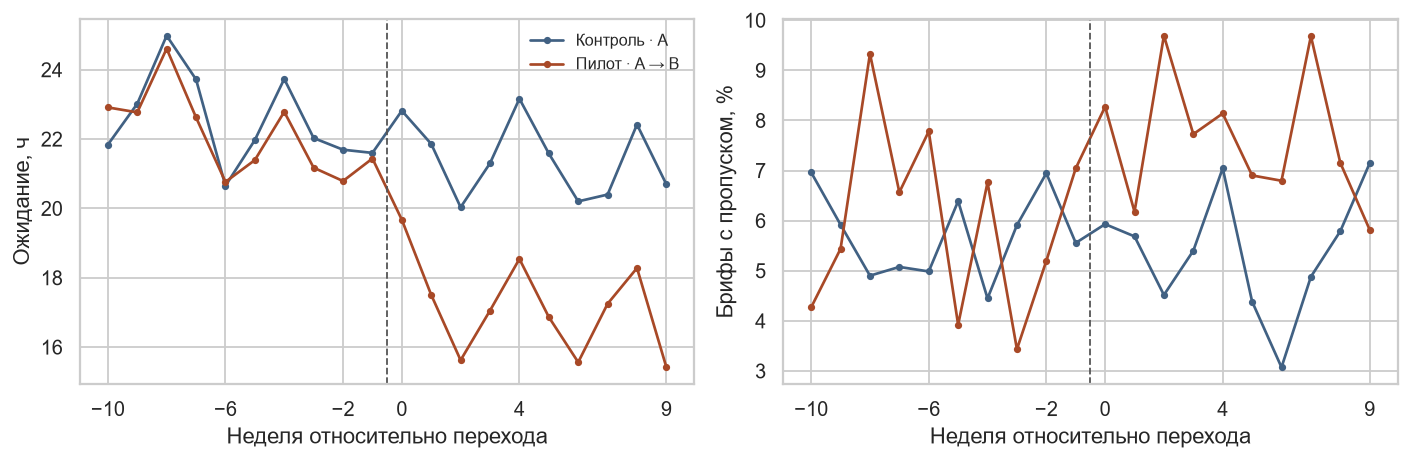

In [4]:
def spread(metric, source=weekly):
    table = source.pivot(index="pair", columns=["pilot", "week"], values=metric)
    return table[1] - table[0]                # Одна траектория разрыва на пару.

def interval(values):
    x = np.asarray(values, dtype=float)
    se = stats.sem(x)
    half = stats.t.ppf(.975, len(x) - 1) * se
    return pd.Series({"Оценка": x.mean(), "Низ 95%": x.mean() - half,
                      "Верх 95%": x.mean() + half})

def paired_change(gaps, before, after):
    return gaps.loc[:, after].mean(axis=1) - gaps.loc[:, before].mean(axis=1)

before, after = WEEKS[WEEKS < 0], WEEKS[WEEKS >= 0]
time_gap, defect_gap = spread("wait_h"), spread("gap_pp")
colors = ["#416183", "#a84927"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, metric, label in zip(axes, ["wait_h", "gap_pp"], ["Ожидание, ч", "Брифы с пропуском, %"]):
    for group, color, name in zip([0, 1], colors, ["Контроль · A", "Пилот · A → B"]):
        series = weekly.loc[weekly.pilot.eq(group)].groupby("week")[metric].mean()
        ax.plot(series.index, series, "o-", ms=3, label=name, color=color)
    ax.axvline(-.5, color="#555555", ls="--", lw=1)
    ax.set(xlabel="Неделя относительно перехода", ylabel=label, xticks=[-10,-6,-2,0,4,9])
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

In [5]:
# Предтренд: наклон разрыва внутри каждой пары; плацебо: «переход» за 5 недель до пилота.
checks = {}
for name, gap in [("Ожидание, ч", time_gap), ("Пропуски, п.п.", defect_gap)]:
    slopes = gap[before].apply(lambda row: stats.linregress(before, row).slope, axis=1)
    placebo = paired_change(gap, before[:5], before[5:])
    for check, values in [("наклон за неделю", slopes), ("плацебо", placebo)]:
        checks[f"{name} · {check}"] = pd.concat([
            interval(values), pd.Series({"p (H0 = 0)": stats.ttest_1samp(values, 0).pvalue})])
print(pd.DataFrame(checks).T.round(3).to_string())
print("Изменение состава и потока, DiD:")
print(pd.DataFrame({m: interval(paired_change(spread(m), before, after))
                    for m in ["complex_pct", "tasks"]}).T.round(2).to_string())

                                   Оценка  Низ 95%  Верх 95%  p (H0 = 0)
Ожидание, ч · наклон за неделю     -0.111   -0.290     0.067       0.209
Ожидание, ч · плацебо              -0.583   -1.598     0.432       0.247
Пропуски, п.п. · наклон за неделю  -0.052   -0.477     0.374       0.804
Пропуски, п.п. · плацебо           -1.685   -4.325     0.955       0.200
Изменение состава и потока, DiD:
             Оценка  Низ 95%  Верх 95%
complex_pct   -0.63    -5.44      4.17
tasks         -0.21    -1.40      0.99


**Что видно до запуска.** Готовность распределена неравномерно по конструкции (SMD 2,03). Поток почти совпадает — 17,72 и 17,74 задачи в неделю, но в пилоте больше сложных задач (37,66% против 35,87%). График времени показывает повторяющиеся пики нагрузки на фоне общего снижения. У групп разный исходный уровень ожидания; на графике пропусков выше недельный шум.

Для времени наклон разрыва составляет −0,11 ч в неделю (95% ДИ от −0,29 до +0,07), а фиктивное внедрение даёт −0,58 ч (от −1,60 до +0,43). Для пропусков плацебо равно −1,69 п.п. (от −4,33 до +0,96). Ни один тест не выявил убедительного расхождения до старта, но интервалы допускают заметный дрейф, особенно у качества. При переходе оценка сдвига доли сложных задач равна −0,63 п.п. (от −5,44 до +4,17). Поэтому допущение о параллельных трендах правдоподобно в заданной симуляции, а его влияние на величину результата стоит проверить сменой спецификации.

## 2. Почему парный Difference-in-Differences

Для каждой команды и недели считаем среднее по задачам. В каждой паре вычитаем из показателя пилота показатель контроля той же недели. Разность средних разрывов после и до внедрения — оценка эффекта для команды, перешедшей на B. Команды и недели имеют равный вес; крупная команда не определяет решение за весь пилот. Это средний эффект на поступающие задачи типичной пилотной команды в наблюдаемом 10-недельном окне.

Для такой трактовки нужны параллельные изменения без B, отсутствие досрочного внедрения и переноса практики между командами. Общие календарные колебания вычитаются внутри недели; постоянные различия в уровне — при сравнении до/после. В симуляции нет обмена агентными сессиями между командами, состав пары фиксирован и переход один. В реальном пилоте одновременное обновление модели только в первой волне нарушило бы идентификацию. Потребовался бы журнал версий, назначений и отклонений.

**Альтернатива.** В новом пилоте лучше случайно назначить порядок перехода команд внутри пар. Индивидуальный A/B возможен при независимых сессиях и неизменном поведении владельца задачи; общий владелец может перенести навыки одного процесса в другой. В нашем сценарии порядок задан готовностью. Для RDD нет общего порога допуска, для IV нет отдельного внешнего инструмента, а сопоставление только по наблюдаемым признакам оставило бы различия в привычной скорости команд.

## 3. Эффект на время утверждения и чувствительность

Для статистического вывода используем 24 независимые парные оценки: двусторонний t-интервал Стьюдента с 23 степенями свободы. Он учитывает, что одна команда ведёт много задач в разные недели. Дополнительно сужаем окно до пяти недель с каждой стороны и экстраполируем линейный предтренд разрыва. Последняя оценка чувствительна к шуму в коротком предысторическом периоде. Все варианты оценивают эффект в часах.

In [6]:
by_pair = paired_change(time_gap, before, after)
pre_slope = time_gap[before].apply(lambda v: stats.linregress(before, v).slope, axis=1)
sensitivity = pd.DataFrame({
    "10 + 10 недель": interval(by_pair),
    "5 + 5 недель": interval(paired_change(time_gap, before[-5:], after[:5])),
    "С линейным предтрендом": interval(by_pair - pre_slope * (after.mean() - before.mean())),
}).T
print(sensitivity.round(2).to_string())
print(f"Парный t-тест эффекта против нуля: p = {stats.ttest_1samp(by_pair, 0).pvalue:.3g}")
leave_one = (by_pair.sum() - by_pair) / (len(by_pair) - 1)
print(f"Поочерёдное исключение одной пары: от {leave_one.min():.2f} до {leave_one.max():.2f} ч.")
completion = interval(paired_change(spread("closed_pct"), before, after))
print("Утверждение за 48 ч, изменение в п.п.:", completion.round(2).to_dict())

                        Оценка  Низ 95%  Верх 95%
10 + 10 недель           -3.87    -4.59     -3.15
5 + 5 недель             -3.47    -4.48     -2.45
С линейным предтрендом   -2.76    -4.37     -1.14
Парный t-тест эффекта против нуля: p = 9.52e-11
Поочерёдное исключение одной пары: от -4.00 до -3.71 ч.
Утверждение за 48 ч, изменение в п.п.: {'Оценка': 2.38, 'Низ 95%': 0.81, 'Верх 95%': 3.96}


**Вывод по времени.** Типичная команда сократила среднее ожидание в первые 48 ч на **3,87 ч** (95% ДИ экономии от **3,15 до 4,59 ч**). Основной эффект превышает порог в 1 ч. В коротком окне экономия равна 3,47 ч, после поправки на линейный предтренд — 2,76 ч (от 1,14 до 4,37). Знак и решение по времени сохраняются; точная величина зависит от допущения о тренде. Поочерёдное исключение пар даёт экономию от 3,71 до 4,00 ч. Одновременно доля задач, утверждённых за 48 ч, выросла на 2,38 п.п. (от 0,81 до 3,96). Для 1 025 задач дальнейшее время ожидания неизвестно по CSV; распространить оценку на полный срок до утверждения нельзя.

## 4. Guardrail: потеря согласованного требования

В симуляции у каждой задачи есть версия брифа для аудита: утверждённая версия либо последний черновик на 48-м часу. Воспроизводим результат слепой бинарной проверки: удалось ли аудитору найти хотя бы один критический пропуск. Критическим считается пропуск, при котором бриф допускает реализацию, нарушающую явно согласованное требование. Например, два независимо подтверждённых pipeline одного SHA должны считаться разными событиями, а бриф допускает их объединение. В реальном пилоте аудитору дают обсуждение и бриф без истории агентов. В CSV нет текстов: метка сгенерирована с указанной в коде вероятностью. Делитель включает также задачи без утверждения.

Проверяем и отличие от нуля, и запас до допустимого вреда. Для решения о расширении нужны **оба** заранее заданных условия по времени и качеству. Это совместное правило пересечения гипотез: единичный удачный тест не разрешает запуск. Для описательных тестов предтренда и чувствительности не выбираем «лучшую» спецификацию по p-значению; оценки по сложности в разделе 6 — разведочные.

In [7]:
defect_did = paired_change(defect_gap, before, after)
guard = interval(defect_did)
defect_slope = defect_gap[before].apply(lambda v: stats.linregress(before, v).slope, axis=1)
defect_specs = {
    "10 + 10 недель": defect_did,
    "5 + 5 недель": paired_change(defect_gap, before[-5:], after[:5]),
    "С линейным предтрендом": defect_did - defect_slope * (after.mean() - before.mean()),
}
guard_table = pd.DataFrame({label: interval(values) for label, values in defect_specs.items()}).T
guard_table["p против нуля"] = [stats.ttest_1samp(values, 0).pvalue for values in defect_specs.values()]
guard_table["Верх ДИ < порога"] = guard_table["Верх 95%"] < DEFECT_GATE
print("Изменение критических пропусков, п.п. (24 пары команд)")
print(guard_table.round({"Оценка": 2, "Низ 95%": 2, "Верх 95%": 2, "p против нуля": 4}).to_string())
print(f"Порог допустимого прироста: +{DEFECT_GATE:.1f} п.п.")
time_pass = sensitivity.iloc[0]["Верх 95%"] < TIME_GATE
quality_pass = guard["Верх 95%"] < DEFECT_GATE
print(f"Выигрыш больше 1 ч подтверждён: {bool(time_pass)}. "
      f"Допустимое качество подтверждено: {bool(quality_pass)}.")

Изменение критических пропусков, п.п. (24 пары команд)
                        Оценка  Низ 95%  Верх 95%  p против нуля  Верх ДИ < порога
10 + 10 недель            1.99     0.14      3.83         0.0361             False
5 + 5 недель              2.86     0.16      5.57         0.0389             False
С линейным предтрендом    2.50    -2.13      7.13         0.2753             False
Порог допустимого прироста: +2.0 п.п.
Выигрыш больше 1 ч подтверждён: True. Допустимое качество подтверждено: False.


**Вывод по качеству.** В основном окне доля брифов с критическим пропуском выросла на **1,99 п.п.** (95% ДИ от **+0,14 до +3,83**), в окне 5 + 5 недель — на **2,86 п.п.** (от **+0,16 до +5,57**). Поправка на линейный предтренд даёт **+2,50 п.п.**, но с более широким интервалом **от −2,13 до +7,13 п.п.** (p = 0,275). Направление точечной оценки сохраняется во всех трёх вариантах. Статистическое свидетельство ухудшения чувствительно к допущению о тренде.

**Решение по заранее заданному порогу одинаково во всех трёх вариантах.** Каждая верхняя граница выше допустимых +2 п.п. Данные допускают неприемлемый рост пропусков, хотя ни один интервал не устанавливает, что порог фактически превышен.

## 5. Продуктовое решение

**Сохранить два независимых брифа как основной процесс. Модифицировать B и повторить ограниченный пилот.** Ни в одной из трёх спецификаций 95%-й интервал по качеству не исключает вред выше +2 п.п. На 100 сопоставимых задач основная оценка соответствует примерно 387 суммарным часам сокращённого ожидания и двум дополнительным брифам с критическим пропуском. Часы ожидания могут перекрываться между задачами; переводить их в зарплатную экономию или в снижение расходов на модель без данных об активной работе, токенах и цене переделки нельзя.

Следующая версия B: после написания брифа ревьюер независимо извлекает из обсуждения обязательные ограничения, затем сверяет каждое с брифом. Это сохраняет один итоговый документ и адресует конкретный риск. На сложных задачах пока сохраняем A. Даже для обычных задач интервал по качеству пересекает предел +2 п.п. (раздел 6), поэтому доказательств для автоматического включения B в этой страте недостаточно. Для решения о расширении нужен новый пилот с теми же двумя порогами, сбалансированный по сложности и с аудитом согласованных требований. Результаты относятся к симуляции; на настоящих сессиях Council эффект неизвестен.

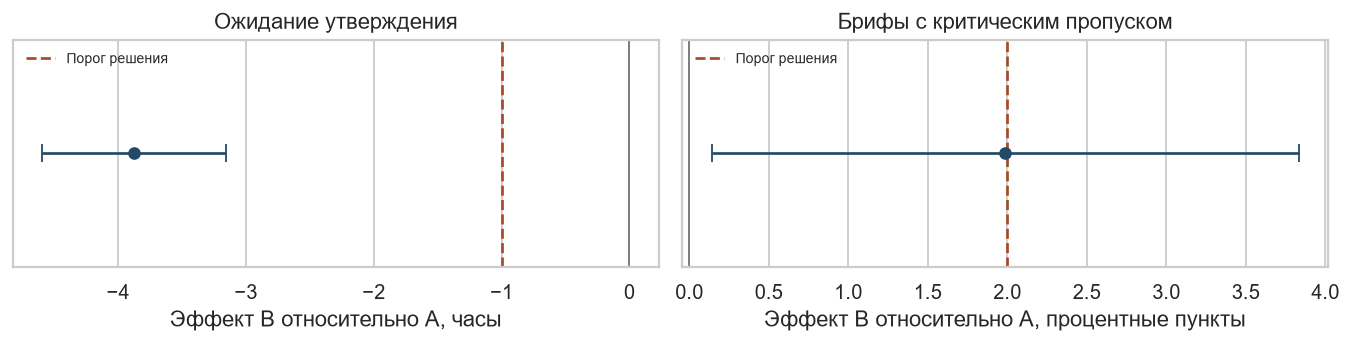

In [8]:
# Один масштаб на метрику: точка — оценка, отрезок — двусторонний 95%-й ДИ.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.8))
for ax, est, threshold, unit, title in [
    (axes[0], sensitivity.iloc[0], TIME_GATE, "часы", "Ожидание утверждения"),
    (axes[1], guard, DEFECT_GATE, "процентные пункты", "Брифы с критическим пропуском"),
]:
    center, lo, hi = est[["Оценка", "Низ 95%", "Верх 95%"]]
    ax.errorbar(center, 0, xerr=[[center-lo], [hi-center]], fmt="o", capsize=5, color="#244a68")
    ax.axvline(0, color="#777777", lw=1)
    ax.axvline(threshold, color="#a84927", ls="--", label="Порог решения")
    ax.set(title=title, xlabel=f"Эффект B относительно A, {unit}", yticks=[], ylim=(-1, 1))
    ax.legend(loc="upper left", fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 6. Бонус: наивное сравнение и неоднородность эффекта

Сравниваем оценки с одинаковым весом команды и недели. Временная разница только в пилоте включает общий прогресс команд. Сравнение только после запуска дополнительно включает исходный разрыв между группами. Для исследования сложности строим раздельные оценки с той же схемой агрегирования; для этого расчёта используем лишь пары с наблюдениями в обоих периодах у обеих команд и показываем фактическое число пар. Внутри подгруппы усредняем доступные недельные значения.

In [9]:
levels = weekly.groupby("pilot").apply(
    lambda g: pd.Series({"До": g.loc[g.week.lt(0), "wait_h"].mean(),
                         "После": g.loc[g.week.ge(0), "wait_h"].mean()}))
levels.index = ["Контроль", "Пилот"]
levels["Изменение"] = levels["После"] - levels["До"]
post_only = levels.loc["Пилот", "После"] - levels.loc["Контроль", "После"]
assert np.isclose(levels.loc["Пилот", "Изменение"] - levels.loc["Контроль", "Изменение"], by_pair.mean())
print("Среднее ожидание, ч:\n", levels.round(2).to_string())
print(f"Только пилот, после минус до: {levels.loc['Пилот', 'Изменение']:.2f} ч. "
      f"Только после, пилот минус контроль: {post_only:.2f} ч. DiD: {by_pair.mean():.2f} ч.")

sub = df.groupby(["complex", "pair", "team", "pilot", "week"], as_index=False)[["wait_h", "gap_pp"]].mean()
segments = {}
for key, subset in sub.groupby("complex"):
    for metric in ["wait_h", "gap_pp"]:
        contrast = spread(metric, subset)
        diffs = paired_change(contrast, before, after).dropna()
        result = interval(diffs)
        result["Пар"] = len(diffs)
        segments[("Сложные" if key else "Обычные", metric)] = result
print(pd.DataFrame(segments).T.round(2).to_string())

Среднее ожидание, ч:
              До  После  Изменение
Контроль  22.52  21.45      -1.08
Пилот     22.13  17.18      -4.95
Только пилот, после минус до: -4.95 ч. Только после, пилот минус контроль: -4.27 ч. DiD: -3.87 ч.
                Оценка  Низ 95%  Верх 95%   Пар
Обычные wait_h   -4.62    -5.27     -3.96  24.0
        gap_pp    1.22    -0.36      2.81  24.0
Сложные wait_h   -2.90    -3.66     -2.13  24.0
        gap_pp    3.03    -1.33      7.39  24.0


**Почему оценки расходятся.** Наивное «до/после» даёт экономию 4,95 ч. За те же недели контроль ускорился на 1,08 ч, поэтому парный DiD оставляет 3,87 ч. Сравнение групп только после внедрения даёт 4,27 ч: пилот был быстрее ещё до старта примерно на 0,39 ч. Расхождения на 0,01 ч при вычитании округлённых значений связаны с округлением.

У обычных задач оценка изменения пропусков составляет +1,22 п.п. (от −0,36 до +2,81), у сложных +3,03 п.п. (от −1,33 до +7,39). Данных недостаточно для утверждения, что эффект различается между стратами: формального подтверждающего теста взаимодействия не планировалось. Оба интервала допускают превышение порога. Поэтому сегментация задаёт приоритет следующей проверки, а не разрешение на внедрение.